# INITI

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np
from torchvision.utils import make_grid,save_image
import os
import cv2  # pip install opencv-python
from torchsummary import summary


In [7]:
import cv2
import numpy as np

def get_circle_center_hough(
    binary_image,
    min_radius=1,
    max_radius=50,
    min_dist=20,
    param1=50,
    param2=10
):


    # Garante uint8
    image = binary_image.astype(np.uint8)

    # Suavização para ajudar o Hough
    blurred = cv2.GaussianBlur(
        image,
        (9, 9),
        2
    )

    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=min_dist,
        param1=param1,
        param2=param2,
        minRadius=min_radius,
        maxRadius=max_radius
    )

    if circles is None:
        return None

    circles = np.round(circles[0]).astype(int)

    # Primeiro círculo detectado
    x, y, radius = circles[0]

    return x, y

In [2]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(ConvBlock, self).__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.conv(x)


class TrackentV2(nn.Module):
    def __init__(self,input_channels = 9):
        super(TrackentV2, self).__init__()
        self.input_channels = input_channels
        #Bloco 1
        self.conv1 = ConvBlock(input_channels, 64)
        self.conv2 = ConvBlock(64, 64)
        

        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) 


        ## Bloco 2
        self.conv3 = ConvBlock(64, 128)
        self.conv4 = ConvBlock(128, 128)

        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)


        # Bloco 3
        self.conv5 = ConvBlock(128, 256)
        self.conv6 = ConvBlock(256, 256)
        self.conv7 = ConvBlock(256, 256)

        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)

        
        self.bottleneck = nn.Sequential(
            ConvBlock(256, 512), #8
            ConvBlock(512, 512), #9
            ConvBlock(512, 512) # 10
        )

        #Nearest -> Ele funciona pegando o pixel mais próximo e replicando ele para preencher a nova dimensão.
        #Bilinear -> Ele faz uma interpolação linear entre os pixels vizinhos para calcular o valor do pixel na nova dimensão. Mas ele pode introduzir artefatos de suavização, especialmente em imagens com bordas nítidas.
        self.up1 = nn.Upsample(
            scale_factor=2, mode='nearest'  
        )

        #Decoder 1
        self.conv11 = ConvBlock(512 + 256, 256) #10 
        self.conv12 = ConvBlock(256, 256) #12
        self.conv13 = ConvBlock(256, 256) #13

        self.up2 = nn.Upsample(
            scale_factor=2, mode='nearest'
        )

        # Decoder 2

        # 256 + 128 = 384
        self.conv14 = ConvBlock(384, 128)
        self.conv15 = ConvBlock(128, 128)


        #Decoder 3 

        self.up3 = nn.Upsample(
            scale_factor=2,
            mode="nearest"
        )

        # 128 + 64 = 192

        self.conv16 = ConvBlock(192, 64)
        self.conv17 = ConvBlock(64, 64)

        self.out = nn.Conv2d(64, 3, kernel_size=1, stride=1, padding=0)

        self.sig = nn.Sigmoid()

    def forward(self,x):

        #Bloco 01
        en1 = self.conv1(x)
        en2 = self.conv2(en1)
        pool1 = self.pool(en2)

        #Bloco 02
        en3 = self.conv3(pool1)
        en4 = self.conv4(en3)
        pool2 = self.pool2(en4)

        # Bloco3

        en5 = self.conv5(pool2)
        en6 = self.conv6(en5)
        en7 = self.conv7(en6)
        pool3 = self.pool3(en7)

        #Bottleneck
        bottleneck = self.bottleneck(pool3)

        up1 = self.up1(bottleneck)
        concat1 = torch.cat((up1, en7), dim=1)
        dec1 = self.conv11(concat1)
        dec2 = self.conv12(dec1)
        dec3 = self.conv13(dec2)

        up2 = self.up2(dec3)
        concat2 = torch.cat((up2, en4), dim=1)

        dec4 = self.conv14(concat2)
        dec5 = self.conv15(dec4)

        up3 = self.up3(dec5)
        concat3 = torch.cat((up3, en2), dim=1)
        dec6 = self.conv16(concat3)
        dec7 = self.conv17(dec6)

        self.output = self.out(dec7)
        if not self.training:
            print("Model eval")
            return self.sig(self.output)
        return self.output


    def show_model_summary(self, input_size=(9, 128, 128)):
        summary(self, input_size=input_size)

  


    



In [3]:

import torch
from torch.utils.data import Dataset
from torchvision.utils import make_grid
from torchvision import transforms
import os
import cv2
import numpy as np

import matplotlib.pyplot as plt

class TracknetV2Dataset(Dataset):
    def __init__(self, frames_path, gts_path, labels_path,original_width, original_height ,input_width=640, input_height=360, debug=False):
        self.frames_path = frames_path
        self.gts_path = gts_path
        self.labels_path = labels_path
        self.samples = []
        self.width = input_width
        self.height = input_height
        self.original_width = original_width
        self.original_height = original_height
        self.debug = debug


        self.transformation = transforms.Compose([
                transforms.ToPILImage(),
                transforms.Resize((self.height, self.width)),
                transforms.ToTensor()
            ])

        self.normalize = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
        self.samples = []
        
        for partidas in sorted(os.listdir(self.frames_path)):
            clips_path = os.path.join(self.frames_path, partidas)
            for clip in sorted(os.listdir(clips_path)):
                frames = sorted(os.listdir(os.path.join(clips_path, clip)))
                for i in range(len(frames)):
                    if i >= 2:
                        path = os.path.join(self.frames_path, partidas, clip, frames[i])
                        path_prev = os.path.join(self.frames_path, partidas, clip, frames[i-1])
                        path_preprev = os.path.join(self.frames_path, partidas, clip, frames[i-2])


                        path_gt = os.path.join(self.gts_path, partidas, clip, frames[i])
                        path_gt_prev = os.path.join(self.gts_path, partidas, clip, frames[i-1])
                        path_gt_preprev = os.path.join(self.gts_path, partidas, clip, frames[i-2])


                        

                        label_path = os.path.join(self.labels_path, partidas, clip, frames[i]).replace('.jpg', '.txt')
                        label_path_prev = os.path.join(self.labels_path, partidas, clip, frames[i-1]).replace('.jpg', '.txt')
                        label_path_preprev = os.path.join(self.labels_path, partidas, clip, frames[i-2]).replace('.jpg', '.txt')
                        
                        self.samples.append((path, path_prev, path_preprev, path_gt, path_gt_prev, path_gt_preprev, label_path, label_path_prev, label_path_preprev))
                

    def __len__(self):
        return len(self.samples)
    
    def __getitem__(self, idx):
        path, path_prev, path_preprev, path_gt, path_gt_prev, path_gt_preprev, label_path, label_path_prev, label_path_preprev = self.samples[idx]

        x = self.get_input(path, path_prev, path_preprev)
        y = self.get_output(path_gt, path_gt_prev, path_gt_preprev)
        labels = self.get_labels(label_path, label_path_prev, label_path_preprev)


        return x, y, labels

    def show_sample(self,idx):
        x, y, labels = self.__getitem__(idx)
        x = dataset.denormalize_9ch(x)

        x1, x2, x3 = torch.chunk(x, 3, dim=0)
        y1, y2, y3 = torch.chunk(y, 3, dim=0)

        data = [x1, x2, x3, y1, y2, y3]

        plt.figure(figsize=(12, 8))

        for i, img in enumerate(data):

            plt.subplot(2, 3, i + 1)
            plt.axis("off")

            if i < 3:
                # [3,H,W] -> [H,W,3]
                img = img.permute(1, 2, 0).cpu().numpy()

                # garantir intervalo [0,1]
                img = np.clip(img, 0, 1)

                # cv2.circle trabalha melhor aqui com uma cópia
                img = img.copy()

                x_pos = int(labels[i][0])
                y_pos = int(labels[i][1])

                cv2.circle(
                    img,
                    (x_pos, y_pos),
                    radius=5,
                    color=(0, 1, 0),
                    thickness=-1
                )

                plt.imshow(img)
                plt.title(f"Input Frame {i + 1}")

            else:
                # GT: [1,H,W] -> [H,W]
                img = img.squeeze(0).cpu().numpy()

                plt.imshow(img, cmap="gray")
                plt.title(f"Ground Truth Frame {i - 2}")

        plt.tight_layout()
        plt.show()
    def get_output(self, path_gt, path_gt_prev, path_gt_preprev):
        img = cv2.imread(path_gt, cv2.IMREAD_GRAYSCALE)
        img_prev = cv2.imread(path_gt_prev, cv2.IMREAD_GRAYSCALE)
        img_preprev = cv2.imread(path_gt_preprev, cv2.IMREAD_GRAYSCALE)

        img = torch.from_numpy(img).unsqueeze(0).float() / 255.0  # Normalize to [0, 1]
        img_prev = torch.from_numpy(img_prev).unsqueeze(0).float() / 255.0  # Normalize to [0, 1]
        img_preprev = torch.from_numpy(img_preprev).unsqueeze(0).float() / 255.0  # Normalize to [0, 1]

        y = torch.cat([img_preprev, img_prev, img], dim=0)  # (3, H, W)

        return y

    def denormalize_9ch(self, tensor):
        """
        tensor: [9, H, W]
        retorna: [9, H, W]
        """

        mean = torch.tensor(
            [0.485, 0.456, 0.406],
            device=tensor.device,
            dtype=tensor.dtype
        ).view(3, 1, 1)

        std = torch.tensor(
            [0.229, 0.224, 0.225],
            device=tensor.device,
            dtype=tensor.dtype
        ).view(3, 1, 1)

        img1, img2, img3 = torch.chunk(tensor, 3, dim=0)

        img1 = img1 * std + mean
        img2 = img2 * std + mean
        img3 = img3 * std + mean

        return torch.cat([img1, img2, img3], dim=0)
    def _get_label_data(self, label_path):
        if not os.path.exists(label_path):
            return 0, 0, 0  # Return default values if the label file doesn't exist

        with open(label_path, 'r') as f:
            lines = f.readlines()

        if len(lines) == 0:
            return 0, 0, 0  # Return default values if the label file is empty

        lines = lines[0].strip().split()

        x_pos = (float(lines[0]) * self.width)/ self.original_width 
        y_pos = (float(lines[1]) * self.height)/ self.original_height 
        vis = int(lines[2]) 


        return x_pos, y_pos, vis

    def get_labels(self, label_path,label_path_prev,label_path_preprev):
        x_pos, y_pos, vis = self._get_label_data(label_path)
        x_pos_prev, y_pos_prev, vis_prev = self._get_label_data(label_path_prev)
        x_pos_preprev, y_pos_preprev, vis_preprev = self._get_label_data(label_path_preprev)

        return [(x_pos_prev, y_pos_prev, vis_prev), (x_pos_preprev, y_pos_preprev, vis_preprev),(x_pos, y_pos, vis)]

        
    def get_input(self, path, path_prev, path_preprev):

        img = cv2.imread(path)
        img_prev = cv2.imread(path_prev)
        img_preprev = cv2.imread(path_preprev)

            # BGR -> RGB
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_prev = cv2.cvtColor(img_prev, cv2.COLOR_BGR2RGB)
        img_preprev = cv2.cvtColor(img_preprev, cv2.COLOR_BGR2RGB)

        img = self.transformation(img)
        img_prev = self.transformation(img_prev)
        img_preprev = self.transformation(img_preprev)

        img = self.normalize(img)
        img_prev = self.normalize(img_prev)
        img_preprev = self.normalize(img_preprev)


        imgs = torch.cat([img_preprev, img_prev, img], dim=0)  # (9, H, W)
        
        return imgs

        

In [4]:
root_path = "../datasets/val"

frames_path = os.path.join(root_path, "frames_out")
gts_path = os.path.join(root_path, "gts")
labels_path = os.path.join(root_path, "labels")

dataset = TracknetV2Dataset(frames_path, gts_path, labels_path, original_width=1920, original_height=1080, input_width=640, input_height=360)

# AB

In [5]:
model = TrackentV2(input_channels=9)

In [6]:

x,y,labels = dataset[0]

print(f"X_SHAPE: {x.shape}, Y_SHAPE: {y.shape}, LABELS: {labels}")

X_SHAPE: torch.Size([9, 360, 640]), Y_SHAPE: torch.Size([3, 360, 640]), LABELS: [(414.3333333333333, 159.0, 1), (414.0, 158.66666666666666, 1), (414.6666666666667, 159.0, 1)]


In [ ]:
import cv2
import numpy as np

def get_circle_center_hough(
    binary_image,
    min_radius=1,
    max_radius=50,
    min_dist=20,
    param1=50,
    param2=10
):


    # Garante uint8
    image = binary_image.astype(np.uint8)

    # Suavização para ajudar o Hough
    blurred = cv2.GaussianBlur(
        image,
        (9, 9),
        2
    )

    circles = cv2.HoughCircles(
        blurred,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=min_dist,
        param1=param1,
        param2=param2,
        minRadius=min_radius,
        maxRadius=max_radius
    )

    if circles is None:
        return None

    circles = np.round(circles[0]).astype(int)

    # Primeiro círculo detectado
    x, y, radius = circles[0]

    return x, y


def postprocessing(prediction, threshold=0.5):
    # Apply sigmoid to get probabilities
    prob_map = prediction

    # Convert to numpy array and squeeze to [H, W]
    prob_map_np = prob_map.squeeze(0).cpu().numpy()

    # Thresholding
    binary_map = (prob_map_np > threshold).astype(np.uint8) * 255

    # Use Hough Circle Transform to detect circles
    center = get_circle_center_hough(binary_map)

    return center

Model eval


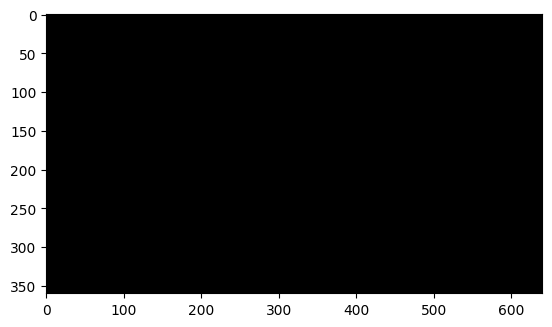

In [25]:
model.eval()
outputs = model(x.unsqueeze(0))  # Add batch dimension
outputs = outputs.squeeze(0)  # Remove batch dimension

o1,o2,o3 = torch.chunk(outputs, 3, dim=0)

o1 = o1.detach().cpu().numpy()
o1 *= 255
o1 = o1.squeeze(0)
o1 = cv2.threshold(o1, 50, 255, cv2.THRESH_BINARY)[1]  # Apply thresholding to convert to binary image
plt.imshow(o1, cmap='gray')

In [ ]:
model.eval()
val_loss = []
tp = [0,0]
fp = [0,0]
tn = [0,0]
fn = [0,0]
max_dist = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

with torch.no_grad():
    for x, y, labels in val_loader:
        inputs, targets = x.to(device), y.to(device)

        outputs = model(inputs)
        loss = criterion(outputs, targets)

        print(f"Validation Batch Loss: {loss.item():.4f}")
        val_loss.append(loss.item())

        
        
        for img_idx in range(outputs.size(0)):
            img_to_show = outputs[img_idx]
            img_to_show = img_to_show.squeeze(0).cpu().numpy()  # (H, W)
            
            x, y = postprocess(img_to_show)
            gt_x, gt_y = labels[img_idx]['x'], labels[img_idx]['y']
            visibility = labels[img_idx]['visibility']
        
            

            if x is not None and y is not None:
                if visibility == 1:  # Ball is visible
                    dist = np.sqrt((x - gt_x) ** 2 + (y - gt_y) ** 2)
                    if dist <= max_dist:
                        tp[visibility] += 1  # True Positive
                    else:
                        fp[visibility] += 1  # False Positive
                else:
                    fp[visibility] += 1  # False Positive (ball not visible but detected)
            else:
                if visibility == 1:  # Ball is visible but not detected
                    fn[visibility] += 1  # False Negative
                else:
                    tn[visibility] += 1  # True Negative (ball not visible and not detected)

print(f"TP (Visible): {tp[1]}, FP (Visible): {fp[1]}, TN (Not Visible): {tn[0]}, FN (Visible): {fn[1]}")
eps = 1e-6
precision = tp[1] / (tp[1] + fp[1] + eps)        
recall = tp[1] / (tp[1] + fn[1] + eps)
f1_score = 2 * (precision * recall) / (precision + recall + eps)  

avg_val_loss = sum(val_loss) / len(val_loss)
